# 17 · What changes when the encoder sees the arrangement?

Tile the same strip vertically to make a 96 × 96 square. Extract the layer 1 and layer 4 maps, with strides 4 and 32. Their global average pooled vectors are the whole-image representations. These inputs deliberately preserve the synthetic lattice and skip classification-time cropping.

The identical central tile has the same isolated embedding. Late contextual features at that location differ by 0.102 in cosine distance. The largest late pooled distance caused by shifting a single arrangement is 0.135, versus 0.099 between the unshifted arrangements.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.patterns import homometric
from observables.stage3 import FAMILIES, CONDITIONS, tile_library, cyclic_statistics
from observables.stage4 import Encoder, reference_images, mean_q_distance, patch_projection, unit
OUT = ROOT/'results'/'stage4'
OUT.mkdir(exist_ok=True, parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

## Hold a local tile fixed and change its context
The two reference strips both have state 1 at site 0. Cyclically shift both by six tiles so that this shared tile lands at the center. The two independent tile embeddings agree. A feature map sampled at the same image position can differ because the encoder receives the whole arrangement. A spatial map cell has a receptive field and is not a separately encoded tile.

In [3]:
encoder=Encoder()
a,b=[np.roll(x,48,axis=1) for x in reference_images()]
np.testing.assert_array_equal(a[:,48:56],b[:,48:56])
isolated=encoder.patch_embeddings(np.stack([a[:,48:56],b[:,48:56]]))
np.testing.assert_allclose(isolated[0],isolated[1],atol=1e-7)
maps=encoder.maps(np.tile(np.stack([a,b]),(1,12,1)),96)
rows=[]
for name,stride,field in zip(['layer 1','layer 4'],[4,32],maps):
    xy=unit(field[:,:,48//stride,52//stride].numpy().astype(float))
    gap=unit(field.mean((2,3)).numpy().astype(float))
    rows.append((name,stride,*field.shape[-2:],1-xy[0]@xy[1],1-gap[0]@gap[1]))
table=pd.DataFrame(rows,columns=['layer','stride','height','width','local cosine distance','GAP cosine distance'])
display(table.round(6));table.to_csv(OUT/'context_audit.csv',index=False)

,layer,stride,height,width,local cosine distance,GAP cosine distance
0,layer 1,4,24,24,0.000000,0.001058
1,layer 4,32,3,3,0.102448,0.078912


## Compare class distance to a change of origin
Encode all 12 cyclic phases of each reference. Relative to phase 0, plot same-arrangement distance at each phase, with the phase-0 distance to the other arrangement as a reference. Padding and striding are part of the actual encoder. Global average pooling cannot guarantee invariance to shifting the image before encoding.

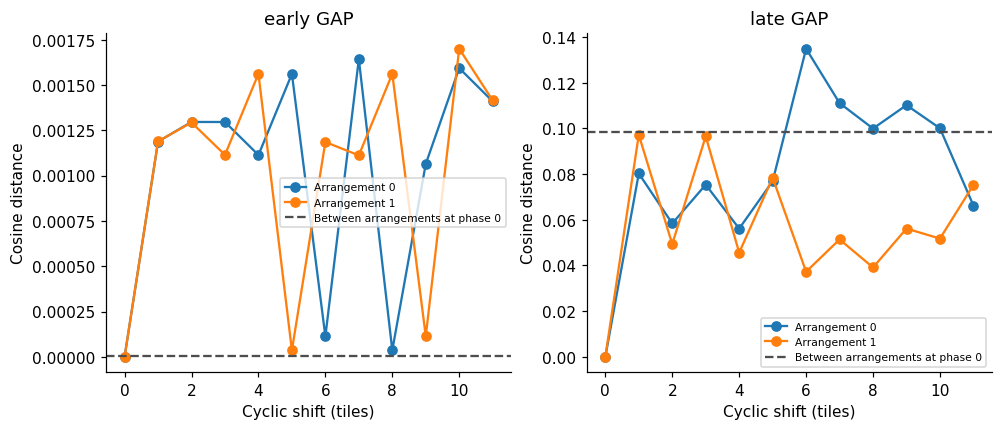

,within,between_at_zero
encoder,,
early GAP,0.00170,0.00000
late GAP,0.13486,0.09854


In [5]:
refs=reference_images()
shifted=[np.roll(im,8*k,axis=1) for im in refs for k in range(12)]
fig,axes=plt.subplots(1,2,figsize=(9,3.8))
rows=[]
for name,z,ax in zip(['early GAP','late GAP'],encoder.whole_embeddings(shifted),axes):
    z=z.reshape(2,12,-1)
    between=1-z[0,0]@z[1,0]
    for label in range(2):
        within=np.maximum(0,1-z[label]@z[label,0])
        ax.plot(np.arange(12),within,'o-',label=f'Arrangement {label}')
        rows.extend((name,label,k,value,between) for k,value in enumerate(within))
    ax.axhline(between,ls='--',color='.3',label='Between arrangements at phase 0')
    ax.set(xlabel='Cyclic shift (tiles)',ylabel='Cosine distance',title=name);ax.legend(fontsize=7)
show('17_whole_embedding_phase')
frame=pd.DataFrame(rows,columns=['encoder','label','shift','within','between_at_zero'])
frame.to_csv(OUT/'phase_audit.csv',index=False)
display(frame.groupby('encoder')[['within','between_at_zero']].max().round(5))

## Interpretation
A whole-image embedding can distinguish clean arrangements that collide under independent patch pooling because the spatial encoder changes the vectors before pooling. The phase sweep tests whether the resulting separation competes with a transformation that the task treats as irrelevant. This experiment does not isolate the relative contributions of the receptive field, padding, and downsampling.